# Driver Reactivation — A/B testing analysis
**Synthetic data only.** No actual drivers, company data or production treatment are involved.

This notebook executes the same modular analysis as the pipeline, using SQL-exported driver metrics. Run the pipeline first. The prospective analysis plan is saved before generation; seed 42 is fixed and never searched for significance.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
from IPython.display import display, Markdown, Image
from src.design import plan, sample_size
from src.validate_data import read_raw, validate, window_rides
from src.calculate_statistics import statistics_by_scope, economic_scenarios, conclusion
from src.run_pipeline import verify_sql
pd.set_option("display.max_columns", 20)

## 1. Prospective design
H0: p(T)=p(C); H1: p(T)≠p(C). Two-sided α=0.05, power=80%, baseline=12%, MDE=2 percentage points. Sample size uses the arcsine effect size and independent two-proportion normal power approximation (equal arms, no continuity correction). It is a prospective target, not observed power. The initial rough 20,000-participant estimate is replaced by the calculated requirement.

Complete randomization shuffles a fixed equal-sized allocation before outcomes are generated. Primary: any completed ride in seven days; secondary: rides per assigned driver, platform revenue, contribution and incentive costs. Assignment is at driver level. Eligibility: no completed rides in the preceding 30 days. There is one confirmatory endpoint and no interim peeking.

In [2]:
design = plan()
assert design == json.loads((ROOT / "reports/analysis_plan.json").read_text())
display(pd.Series(design, name="Pre-specified plan"))
print("Participants per group:", sample_size())

baseline                                                         0.12
mde_absolute                                                     0.02
alpha                                                            0.05
power                                                             0.8
required_per_arm                                                 4433
total_assigned                                                   8866
allocation              complete randomization, fixed equal arm sizes
H0                                            p_treatment = p_control
H1                                           p_treatment != p_control
primary             at least one completed ride in [assignment, as...
secondary           [rides per assigned driver, platform revenue, ...
analysis            intention-to-treat; two-sided pooled z-test; N...
segments            exploratory country comparisons; no subgroup r...
economic_model      revenue is platform commission in RUB-equivale...
as_of               

Participants per group: 4433


## 2. Data quality and observation window
Validate nulls, duplicates, schema/types, foreign keys, signup dates, inactivity, group values, maturity and exact bonus coverage. Ride events exactly at assignment are included; events exactly seven days later are excluded. Never remove assigned zero-ride drivers. Extraction is at 2025-05-16 UTC; the latest cohort has seven complete observation days.

In [3]:
data = read_raw()
counts = validate(data)
display(pd.Series(counts, name="Rows"))
display(pd.DataFrame({name: {"nulls": int(df.isna().sum().sum()), "duplicate_primary_keys": int(df.iloc[:,0].duplicated().sum())} for name, df in data.items()}).T)
for name, df in data.items():
    print(name, df.dtypes.astype(str).to_dict())
metrics = pd.read_csv(ROOT / "data/processed/driver_metrics.csv", parse_dates=["assigned_at"])
verify_sql(data, metrics)
assert len(metrics) == len(data["experiment_assignments"])
print("Zero-ride assigned drivers:", int((metrics.completed_rides == 0).sum()))
display(metrics.groupby("variant").agg(assigned=("driver_id","size"), returned=("reactivated","sum"), rate=("reactivated","mean"), avg_rides=("completed_rides","mean")))

drivers                    8866
experiment_assignments     8866
rides                     12626
bonus_payments              330
Name: Rows, dtype: int64

,nulls,duplicate_primary_keys
drivers,0,0
experiment_assignments,0,0
rides,0,0
bonus_payments,0,0


drivers {'driver_id': 'int64', 'country': 'object', 'signup_date': 'datetime64[ns, UTC]'}
experiment_assignments {'driver_id': 'int64', 'variant': 'object', 'assigned_at': 'datetime64[ns, UTC]'}
rides {'ride_id': 'int64', 'driver_id': 'int64', 'completed_at': 'datetime64[ns, UTC]', 'revenue': 'float64'}
bonus_payments {'payment_id': 'int64', 'driver_id': 'int64', 'paid_at': 'datetime64[ns, UTC]', 'amount': 'float64'}
Zero-ride assigned drivers: 7742


,assigned,returned,rate,avg_rides
variant,,,,
control,4433,498,0.112339,0.342206
treatment,4433,626,0.141214,0.445297


## 3. SRM and primary inference
The chi-square statistic compares assignment counts with a 1:1 expectation. Because exact equal allocation is enforced by design, the overall p-value is structurally 1. It is only an integrity check after ingestion; it does not independently prove correct randomization. Country counts were not fixed.

Primary inference uses a pooled two-proportion z-test, and a Newcombe interval for the difference of independent proportions, based on Wilson score intervals. The interval is for treatment minus control, in proportion units; multiply by 100 for percentage points. The difference interval and pooled test are related but are not exact inverses. Relative uplift is undefined if control rate is zero.

In [4]:
results = statistics_by_scope(metrics)
saved = pd.read_csv(ROOT / "data/dashboard/statistical_results.csv")
pd.testing.assert_frame_equal(results, saved, check_exact=False, rtol=1e-10)
r = results.iloc[0]
display(results[["scope","n_control","n_treatment","rate_control","rate_treatment","absolute_uplift","relative_uplift","ci_low","ci_high","p_value","srm_p_value"]])
print(f"Uplift {r.absolute_uplift*100:.3f} pp, Newcombe 95% CI [{r.ci_low*100:.3f}, {r.ci_high*100:.3f}] pp; p={r.p_value:.6g}")

,scope,n_control,n_treatment,rate_control,rate_treatment,absolute_uplift,relative_uplift,ci_low,ci_high,p_value,srm_p_value
0,ALL,4433,4433,0.112339,0.141214,0.028874,0.257028,0.015031,0.042727,0.000044,1.000000
1,BY,517,522,0.102515,0.147510,0.044995,0.438914,0.004687,0.085376,0.028394,0.876728
2,KZ,1002,1026,0.139721,0.155945,0.016225,0.116124,-0.014747,0.047128,0.303508,0.594076
3,RU,2914,2885,0.104667,0.134835,0.030168,0.288230,0.013465,0.046903,0.000402,0.703336


Uplift 2.887 pp, Newcombe 95% CI [1.503, 4.273] pp; p=4.39484e-05


## 4. Secondary metrics and distribution
Rides per assigned driver is zero-inflated and right-skewed. Welch comparisons use independent driver-level observations, include zeroes and allow unequal variances; the large-sample mean comparison does not assume individual ride counts are normally distributed. Country and secondary tests are exploratory, unadjusted for multiplicity. A significant country test and a nonsignificant country test do not establish heterogeneity; an interaction test and a larger stratified experiment would be needed.

completed_rides                                                \
                    count      mean       std  min  25%  50%  75%   max   
variant                                                                   
control            4433.0  0.342206  1.173361  0.0  0.0  0.0  0.0  14.0   
treatment          4433.0  0.445297  1.348300  0.0  0.0  0.0  0.0  14.0   

          revenue             ... bonus_cost        contribution_after_bonus  \
            count       mean  ...        75%    max                    count   
variant                       ...                                              
control    4433.0  47.418193  ...        0.0    0.0                   4433.0   
treatment  4433.0  60.106684  ...        0.0  300.0                   4433.0   

                                                                 
                mean        std     min  25%  50%  75%      max  
variant                                                          
control    18.967277  66.500288    0.00  0.0  0.0  0.0  803.744  
treatment   1.710167  40.193686 -218.48  0.0  0.0  0.0  474.884  

[2 rows x 32 columns]

,variant,completed_rides,drivers
0,control,0,3935
1,control,1,118
2,control,2,120
3,control,3,104
4,control,4,62
5,control,5,38
6,control,6,23
7,control,7,15
8,control,8,10
9,control,9,1


,scope,rides_p_value_exploratory,absolute_uplift,ci_low,ci_high
0,ALL,0.000124,0.028874,0.015031,0.042727
1,BY,0.034805,0.044995,0.004687,0.085376
2,KZ,0.076787,0.016225,-0.014747,0.047128
3,RU,0.004898,0.030168,0.013465,0.046903


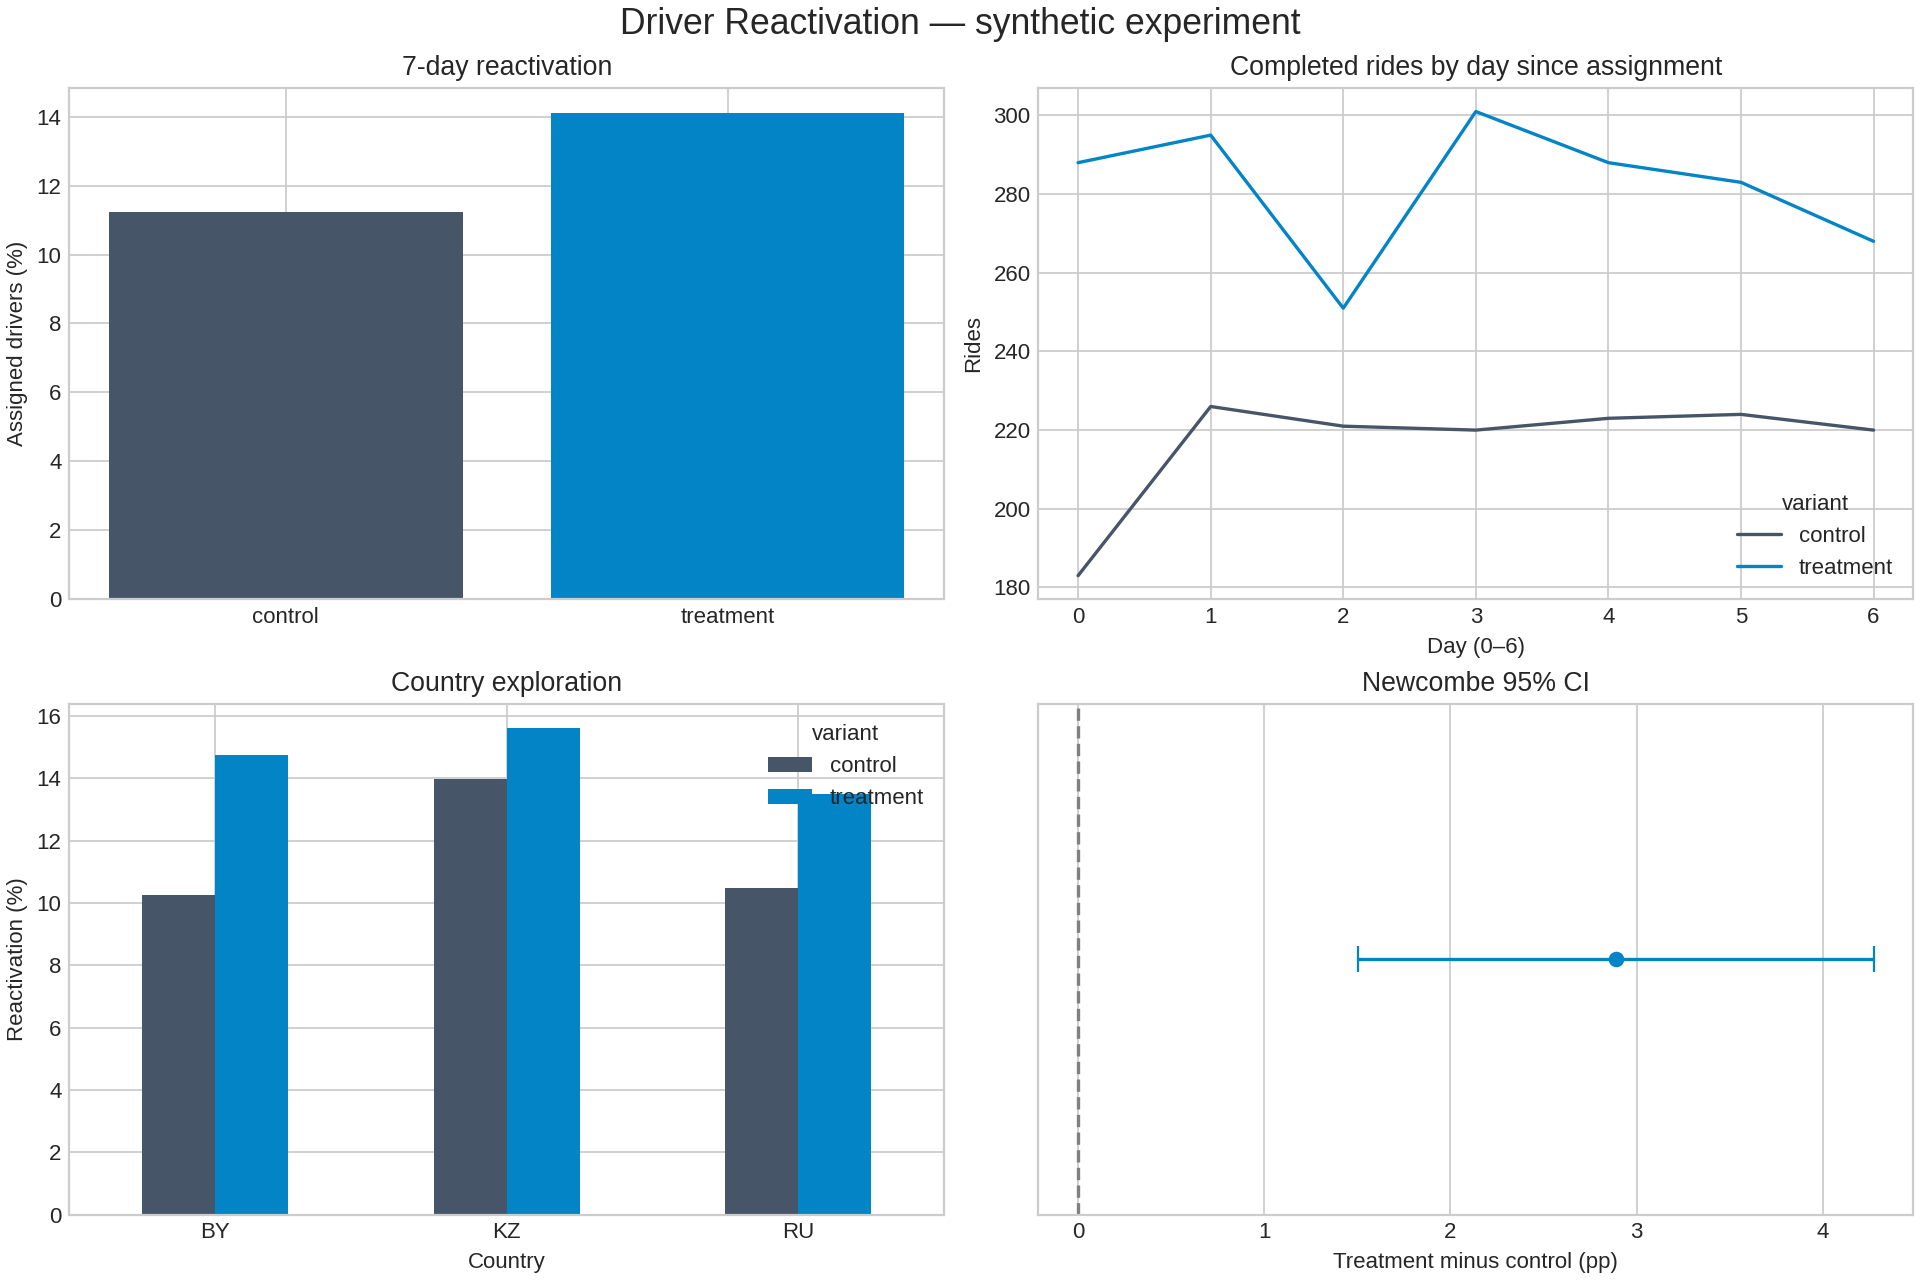

In [5]:
display(metrics.groupby("variant")[["completed_rides","revenue","bonus_cost","contribution_after_bonus"]].describe())
display(metrics.groupby(["variant","completed_rides"]).size().rename("drivers").reset_index().head(24))
display(results[["scope","rides_p_value_exploratory","absolute_uplift","ci_low","ci_high"]])
display(Image(filename=str(ROOT / "reports/analysis.png")))

## 5. Economics and practical significance
`revenue` is simulated **platform commission**, not GMV or profit, measured consistently in RUB-equivalent across countries. Contribution before incentives is revenue × 40%; the model excludes fixed costs, fraud and opportunity costs. Net incremental contribution is treatment size × (treatment mean after bonuses − control mean after bonuses), not the total contribution in treatment. Its 95% Welch interval accounts for driver-level sampling variation, not margin-model uncertainty.

MDE is a planning parameter; a statistically significant effect can still be unprofitable. Alternative bonus scenarios below hold behavior fixed and are sensitivity calculations, not predictions of response to a lower bonus.

In [6]:
scenarios = economic_scenarios(metrics)
display(scenarios)
display(results[["scope","bonus_cost","net_incremental_contribution","net_ci_low","net_ci_high"]])
display(Markdown("### Calculated recommendation\n" + conclusion(r.to_dict())))
best = results.loc[results.scope != "ALL"].sort_values("absolute_uplift", ascending=False).iloc[0]
print(f"Largest observed country effect: {best.scope}, {best.absolute_uplift*100:.2f} pp (exploratory).")

,margin_rate,bonus_amount,incremental_revenue,qualifiers,net_incremental_contribution
0,0.2,0.0,56248.08,330,11249.616
1,0.2,50.0,56248.08,330,-5250.384
2,0.2,150.0,56248.08,330,-38250.384
3,0.2,300.0,56248.08,330,-87750.384
4,0.4,0.0,56248.08,330,22499.232
5,0.4,50.0,56248.08,330,5999.232
6,0.4,150.0,56248.08,330,-27000.768
7,0.4,300.0,56248.08,330,-76500.768
8,0.6,0.0,56248.08,330,33748.848
9,0.6,50.0,56248.08,330,17248.848


,scope,bonus_cost,net_incremental_contribution,net_ci_low,net_ci_high
0,ALL,99000.0,-76500.768000,-86642.431184,-66359.104816
1,BY,11100.0,-6699.052093,-9932.757348,-3465.346837
2,KZ,27300.0,-22598.940814,-27544.298973,-17653.582656
3,RU,60600.0,-47275.357931,-55514.101695,-39036.614167


### Calculated recommendation
Reactivation increased with a statistically significant two-sided result. Do not roll out the current offer: the modeled net contribution is negative, including its 95% interval.

Largest observed country effect: BY, 4.50 pp (exploratory).


## 6. Product follow-up and limitations
Do not generalize a seeded simulation to actual drivers. Test reduced incentives and alternate qualification thresholds, with fresh planning and real contribution margins. Measure 28-day sustained activity, cannibalization, fraud and spillovers. The current primary endpoint is seven-day reactivation; the daily series describes repeat activity, not long-term retention.

BI outputs contain full-cohort and country-level precomputed inference. Assignment-date and variant filters apply to descriptive charts; they must not silently alter the inferential population. No hosted DataLens dashboard or production effect is claimed.